# Statistics slice (Asif): return properties, why we forecast volatility, and stationarity
These cells only read `data/processed/model_table.csv` and only use the **training rows** (`split == "train"`, 2005-03-30 to 2014-12-23). Nothing here touches the test years.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os
import sys

if os.path.basename(os.getcwd()) == "econometric":   # same as the other slices: run from the repo root
    os.chdir("../..")
sys.path.append(os.getcwd())

TARGET = "y"                               # log of next-5-day realised volatility
FEATURES = [f"f{i}" for i in range(1, 11)]  # f1 ... f10
os.makedirs("results/figures", exist_ok=True)

table = pd.read_csv("data/processed/model_table.csv", parse_dates=["date"])
train = table[table["split"] == "train"].reset_index(drop=True)
r = train["f5"]                            # f5 = today's SPY log return (sign kept)
print("Training rows:", len(train), "| returns used:", len(r))

Training rows: 2452 | returns used: 2452


### Return properties
Daily returns have a mean near zero and very fat tails (excess kurtosis about 14, where a normal distribution has 0). Skewness is only slightly negative (about −0.09) because 2008 had very large up-days as well as falls.

In [2]:
props = pd.Series({
    "mean (%)": r.mean() * 100,
    "std (%)": r.std() * 100,
    "annualised vol (%)": r.std() * np.sqrt(252) * 100,
    "skewness": stats.skew(r),
    "excess kurtosis": stats.kurtosis(r),   # 0 for a normal distribution
    "min (%)": r.min() * 100,
    "max (%)": r.max() * 100,
})
jb = stats.jarque_bera(r)
print(props.round(3).to_string())
print(f"Jarque-Bera = {jb.statistic:.1f}, p = {jb.pvalue:.2g}  (p < 0.05 -> returns are not normal)")

mean (%)               0.027
std (%)                1.295
annualised vol (%)    20.562
skewness              -0.093
excess kurtosis       14.031
min (%)              -10.365
max (%)               13.557
Jarque-Bera = 20116.0, p = 0  (p < 0.05 -> returns are not normal)


### Why volatility and not returns
If returns were predictable, their autocorrelation would be large. In our training years it is small (|ρ| ≤ 0.09) and switches sign from lag to lag, so it is too weak to forecast with. A few lags poke just outside the 95% band, mostly from the 2008 crisis. Absolute returns (how big the move was) have autocorrelation between 0.26 and 0.42 at every lag up to a month: big moves follow big moves. That is volatility clustering, and it is why we forecast volatility.

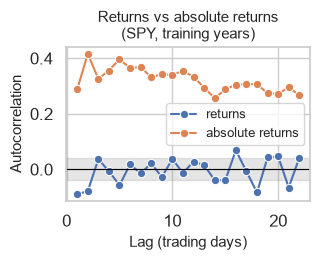

series  absolute returns  returns
lag                              
1                  0.288   -0.089
5                  0.396   -0.057
22                 0.267    0.041
95% band: +/-0.040


In [3]:
lags = range(1, 23)                       # up to about one month
acf = pd.DataFrame({
    "lag": list(lags) * 2,
    "autocorrelation": [r.autocorr(k) for k in lags] + [r.abs().autocorr(k) for k in lags],
    "series": ["returns"] * len(lags) + ["absolute returns"] * len(lags),
})
band = 1.96 / np.sqrt(len(r))             # 95% band if there were no autocorrelation

sns.set_theme(style="whitegrid", font_scale=1.1)   # same as Main_Notebook
fig, ax = plt.subplots(figsize=(3.5, 2.8))
sns.lineplot(data=acf, x="lag", y="autocorrelation", hue="series", marker="o", ax=ax)
ax.axhspan(-band, band, color="grey", alpha=0.2)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Returns vs absolute returns\n(SPY, training years)", fontsize=11)
ax.set_xlabel("Lag (trading days)", fontsize=11)
ax.set_ylabel("Autocorrelation", fontsize=11)
ax.legend(fontsize=9, loc="center right")
fig.tight_layout()
fig.savefig("results/figures/acf_returns_vs_abs.png", dpi=300)
plt.show()

print(acf.pivot(index="lag", columns="series", values="autocorrelation").loc[[1, 5, 22]].round(3))
print(f"95% band: +/-{band:.3f}")

### Stationarity (ADF and KPSS)
The two tests have opposite null hypotheses, so we use both:
- **ADF**: null = non-stationary (unit root). Small p -> stationary.
- **KPSS**: null = stationary. Small p -> non-stationary.

A series is called stationary when ADF p < 0.05 **and** KPSS p > 0.05. KPSS p-values are only tabulated between 0.01 and 0.10, so statsmodels caps them there.

In [4]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss

rows = []
for col in [TARGET] + FEATURES:
    x = train[col].dropna()
    adf_stat, adf_p, *_ = adfuller(x, autolag="AIC")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")    # warning when the p-value is outside the table
        kpss_stat, kpss_p, *_ = kpss(x, regression="c", nlags="auto")
    if adf_p < 0.05 and kpss_p > 0.05:
        verdict = "stationary"
    elif adf_p >= 0.05 and kpss_p <= 0.05:
        verdict = "non-stationary"
    else:
        verdict = "mixed"
    rows.append({"series": col, "ADF stat": adf_stat, "ADF p": adf_p,
                 "KPSS stat": kpss_stat, "KPSS p": kpss_p, "verdict": verdict})

stationarity = pd.DataFrame(rows).round(3)
stationarity.to_csv("results/stationarity_table.csv", index=False)
stationarity

,series,ADF stat,ADF p,KPSS stat,KPSS p,verdict
0,y,-5.406,0.000,0.976,0.010,mixed
1,f1,-7.079,0.000,0.859,0.010,mixed
2,f2,-5.423,0.000,0.964,0.010,mixed
3,f3,-2.956,0.039,0.965,0.010,mixed
4,f4,-2.965,0.038,1.265,0.010,mixed
5,f5,-10.588,0.000,0.264,0.100,stationary
6,f6,-2.494,0.117,2.073,0.010,non-stationary
7,f7,-3.009,0.034,1.200,0.010,mixed
8,f8,-6.458,0.000,0.098,0.100,stationary
9,f9,-12.228,0.000,0.028,0.100,stationary


**Reading the table.** Four features (f5, f8, f9 and f10) are stationary on both tests. The target y and f1–f4 and f7 are *mixed*: ADF rejects a unit root, but KPSS rejects stationarity. That is typical of volatility series, which are very persistent (long memory), and it is exactly the persistence HAR uses. KPSS p-values are only tabulated between 0.01 and 0.10, so 0.010 means "0.01 or less" and 0.100 means "0.10 or more". Only f6 (bond volatility) fails both tests (ADF p = 0.117, KPSS p = 0.01); the next cell looks at why.

In [5]:
# f6 (TLT log volatility) is the only series that fails both tests: look at its level over the training years
tlt_vol = np.exp(train["f6"]) * np.sqrt(252 / 22) * 100   # annualised %
periods = pd.cut(train["date"], bins=pd.to_datetime(["2005-01-01", "2008-01-01", "2010-01-01", "2015-01-01"]),
                 labels=["2005-2007", "2008-2009", "2010-2014"], right=False)
print(tlt_vol.groupby(periods, observed=True).agg(["mean", "median"]).round(1))

           mean  median
date                   
2005-2007   8.6     8.5
2008-2009  17.1    16.3
2010-2014  14.5    13.4


**Result.** TLT volatility changed level over the training years: a mean of 8.6% a year in 2005–2007, 17.1% in 2008–2009 and 14.5% in 2010–2014. So f6 does not settle around one long-run mean, which is what both tests pick up. We keep it, because the features were frozen before the test run and f6 has little weight in the final models (Elastic Net coefficient −0.017, `slices/linear_ml/elastic_net_model.ipynb` section 9). We report it as a limitation rather than change the features after the test.

In [6]:
# Leverage effect: is next week's volatility higher after big falls than after big rises? (training rows only)
big_fall = r <= r.quantile(0.10)
big_rise = r >= r.quantile(0.90)
to_pct = lambda log_vol: np.exp(log_vol) * np.sqrt(252 / 5) * 100   # log 5-day volatility -> annualised %
for name, rows in [("after the largest 10% of falls", big_fall), ("after the largest 10% of rises", big_rise)]:
    print(f"Next-week log volatility {name}: {train.loc[rows, TARGET].mean():.2f} "
          f"(about {to_pct(train.loc[rows, TARGET].mean()):.0f}% annualised), {rows.sum()} days")

Next-week log volatility after the largest 10% of falls: -3.44 (about 23% annualised), 246 days
Next-week log volatility after the largest 10% of rises: -3.70 (about 18% annualised), 246 days


**Result.** In the training years, next-week log volatility averages −3.44 (about 23% annualised) after the largest 10% of daily falls, against −3.70 (about 18%) after the largest 10% of rises. Volatility is higher after big falls than after big rises: the leverage effect, which is why f5 (today's return with its sign) and f10 (last month's return) are features. These are the numbers quoted in the report's features section.